In [29]:
# Useful starting lines
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load data

In [40]:
from helper import load_data, normalize_data

data = load_data()
N, d = data.shape
print("Number of data points: ", N)
print("Dimension of each data point: ", d)

Number of data points:  272
Dimension of each data point:  2


### Initialize your cluster centers

In [41]:
import random
def initialize_clusters(data, k):
    """randomly initialize the k cluster centers (the means). Make sure you choose k clusters from the data itself,
             or ensure otherwise that your initializations have the same scale as the data

    Args:
        data: shape = (N, d). original data.
        k: integer number. predefined number of clusters for the k-means algorithm.
    Returns:
        numpy array with shape (k, d) which corresponds to the k initial clusters.
    """
    ####################################
    ### ___ Enter your code here ___ ###
    ####################################
    k_cluster_centers = []

    for _ in range (k):
        rnd_idx = random.randint(0,len(data)-1)
        k_cluster_centers.append(data[rnd_idx])
    return np.array(k_cluster_centers)



### Update k-means parameters

#### Build distance matrix
Build a distance matrix, collecting the distances of the original dataset to the means of the clusters.

NOTE: once you finish your `build_distance_matrix`, please copy the function to the `helper.py` function. Otherwise, the `kmeans` function will not work.

In [42]:
def build_distance_matrix(data, mu):
    """builds a distance matrix.

    Args:
        data: numpy array of shape = (N, d). original data.
        mu:   numpy array of shape = (k, d). Each row corresponds to a cluster center.
    Returns:
        numpy array of shape (N, k):
            squared distances matrix,
            the value row i column j corresponds to the squared distance of datapoint i with cluster center j.
    """
    ####################################
    ### ___ Enter your code here ___ ###
    ####################################
    matrix = []
    for i in range (len(data)):
        matrix.append([])
        for j in range (len(mu)):
            distance_point = np.linalg.norm(data[i] - mu[j]) ** 2   # added ** 2
            matrix[i].append(distance_point)
    return np.array(matrix)                                         # was: return matrix


#### Update k-means parameters

In [43]:
def update_kmeans_parameters(data, mu_old):
    """compute one step of the kmeans algorithm: using mu_old, find to which cluster each datapoint belongs to,
            then update the parameter cluster centers.

    Args:
        data:   numpy array of shape = (N, d). original data.
        mu_old: numpy array of shape = (k, d). Each row corresponds to a cluster center.
    Returns:
        losses: shape (N, ), contains the (old) squared distances of each data point to its (old) cluster mean (computed from mu_old).
        assignments: vector of shape (N, ) which contains the cluster associated to each data point.
        mu: updated vector mu of shape (k, d) where each row corresponds to the new cluster center.
    """
    ####################################
    ### ___ Enter your code here ___ ###
    ####################################
    matrix_distances = build_distance_matrix(data,mu_old)

    # For each point, pick the closest cluster and record that distance
    assignments = np.argmin(matrix_distances, axis=1)   # (N,)
    losses = np.min(matrix_distances, axis=1)           # (N,)

    # Update each center to the mean of the points assigned to it
    #k, d = len(mu_old[0]), len(mu_old[:][0])
    k, d = mu_old.shape
    mu = np.zeros((k, d))
    for j in range(k):
        members = data[assignments == j]
        if len(members) > 0:
            mu[j] = members.mean(axis=0)
        else:
            mu[j] = mu_old[j]   # empty cluster: keep the old center

    return losses, assignments, mu

#### Play with k-means

The current iteration of k-means is: 0, the average loss is 79.11136678308824.


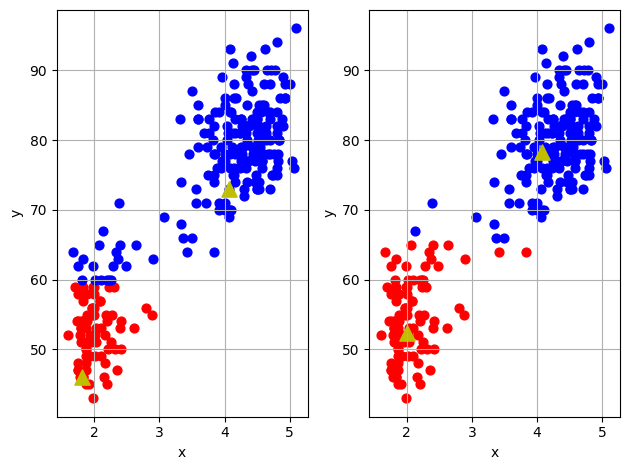

The current iteration of k-means is: 1, the average loss is 36.9980686941959.


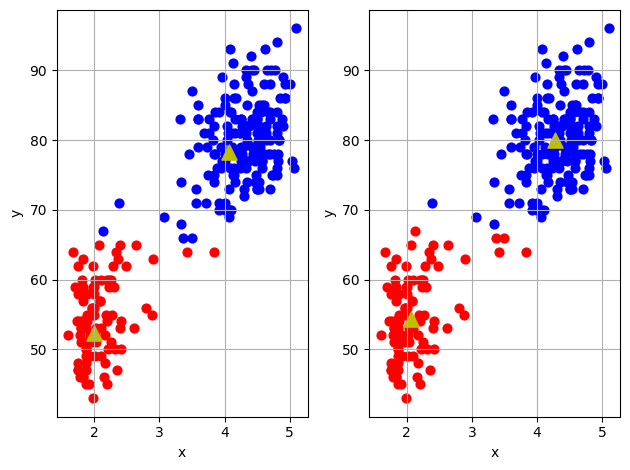

The current iteration of k-means is: 2, the average loss is 32.811048531641894.


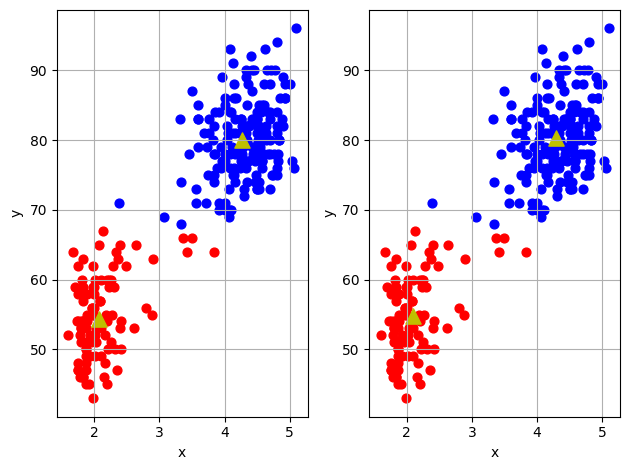

The current iteration of k-means is: 3, the average loss is 32.72709088583533.


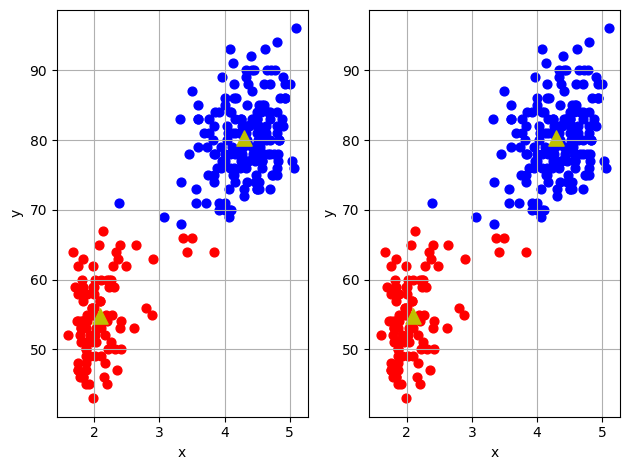

The current iteration of k-means is: 4, the average loss is 32.72709088583533.


In [44]:
from helper import build_dir
from plots import plot


def kmeans(data, k, max_iters, threshold, verbose=True):
    """run the k-means algorithm."""
    output_figure = "kmeans_figures/"
    # initialize the cluster.
    mu_old = initialize_clusters(data, k)
    # init some empty lists to store the result.
    loss_list = []

    # start the kmeans algorithm.
    for iteration in range(max_iters):
        # update z and mu
        losses, assignments, mu = update_kmeans_parameters(data, mu_old)
        # calculate the average loss over all points
        average_loss = np.mean(losses)
        loss_list.append(average_loss)
        if verbose:
            print(
                f"The current iteration of k-means is: {iteration}, the average loss is {average_loss}."
            )
        # check convergence
        if iteration > 0 and np.abs(loss_list[-1] - loss_list[-2]) < threshold:
            break
        # output plot
        if verbose:
            plot(data, mu, mu_old, output_figure + "kmean_iter{i}".format(i=iteration))
        # update k-means information.
        mu_old = mu
    return average_loss


# define parameters
k = 2
max_iters = 10
threshold = 1e-5
output_figure = "kmeans_figures/"

# build figure dir
build_dir(output_figure)

# run kmeans algorithm
average_loss = kmeans(data, k, max_iters, threshold)

### Plotting the loss as a function of number of clusters

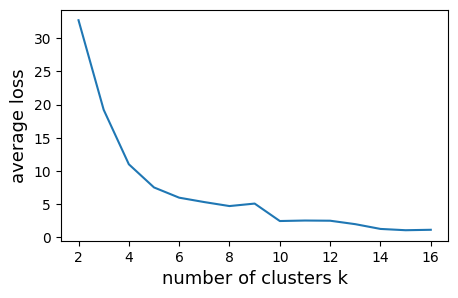

In [45]:
# don't worry about empty slice warnings
import warnings

warnings.filterwarnings("ignore")

losses = []
ks = np.arange(2, 17)
for k in ks:
    average_loss = kmeans(data, k, max_iters, threshold, verbose=False)
    losses += [average_loss]
plt.figure(figsize=(5, 3))
plt.xlabel("number of clusters k", fontsize=13)
plt.ylabel("average loss", fontsize=13)
plt.plot(ks, losses)
plt.show()

## Using k-means for image compression

#### load image

In [46]:
from helper import load_image

image_path = "mandrill.png"
original_image = load_image(image_path)
print(
    "Original image: the shape of image={s}, the data type={dt}.".format(
        s=original_image.shape, dt=original_image.dtype
    )
)

Original image: the shape of image=(480, 480, 3), the data type=float32.


#### preprocess image

In [47]:
def preprocess_image(original_image):
    """preprocess the image.
    vectorize the three matrices (each matrix corresponds to a RGB color channel). **don't normalize!**

    Args:
        original_image: numpy array of shape (480, 480, 3)
    Returns:
        processed_image: numpy array of shape (480*480, 3)
    """
    ####################################
    ### ___ Enter your code here ___ ###
    ####################################
    processed_image =  original_image.reshape(-1, 3)
    return processed_image

processed_image = preprocess_image(original_image)

The current iteration of kmeans is: 0, the average loss is 0.05300197750329971.
The current iteration of kmeans is: 1, the average loss is 0.027887024644652647.
The current iteration of kmeans is: 2, the average loss is 0.02571102486477789.
The current iteration of kmeans is: 3, the average loss is 0.025369985030350813.
The current iteration of kmeans is: 4, the average loss is 0.025251580896218956.
The current iteration of kmeans is: 5, the average loss is 0.02518894972935625.
The current iteration of kmeans is: 6, the average loss is 0.025152495795389338.
The current iteration of kmeans is: 7, the average loss is 0.025130659472221498.
The current iteration of kmeans is: 8, the average loss is 0.0251177131460295.
The current iteration of kmeans is: 9, the average loss is 0.025109769683178004.
The current iteration of kmeans is: 10, the average loss is 0.02510500436436648.
The current iteration of kmeans is: 11, the average loss is 0.025102214757388656.
The current iteration of kmeans 

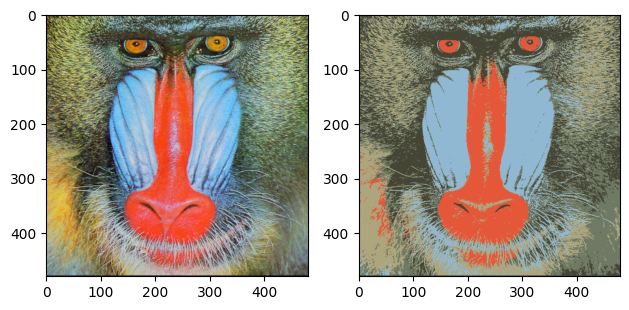

In [49]:
from plots import plot_image_compression


def kmean_compression(original_image, processed_image, k, max_iters, threshold):
    """using k-means for image compression.
    Args:
        original_image: numpy array of shape (480, 480, 3).
        processed_image: numpy array of shape (480*480, 3).
        k: scalar. Number of clusters.
        max_iters: integer. Max number of iterations for the kmeans algorithm.
        threshold: scalar. Stop the kmeans algorithm if the loss decrease between two iterations
                        is lower than the threshold.
    """

    ####################################
    ### ___ Enter your code here ___ ###
    ####################################
    mu_old = initialize_clusters(processed_image, k)

    # run k-means
    old_loss = np.inf
    for iter in range(max_iters):
        # assign each pixel to its nearest center, then recompute the centers
        losses, assignments, mu = update_kmeans_parameters(processed_image, mu_old)

        average_loss = np.mean(losses)
        print("The current iteration of kmeans is: {i}, the average loss is {l}.".format(
            i=iter, l=average_loss))

        # stop once the loss barely decreases
        if np.abs(old_loss - average_loss) < threshold:
            break

        # carry the new centers and loss into the next iteration
        old_loss = average_loss
        mu_old = mu


    # plot histogram
    plot_image_compression(original_image, processed_image, assignments, mu, k)


# define parameters
k = 5
max_iter = 100
threshold = 1e-7

# use kmeans to compress image
kmean_compression(original_image, processed_image, k, max_iter, threshold)